Exercise 6.3 : 

Forecasting/emulating fluid flow past cylinder, Book, Chapter 6, page
248. Bonus analysis: compare RNN, LSTM, GRU, ESN, TST, etc. Try and
understand at least one architecture in detail (some detailed in slides and some are
not).

DISCLAIMER: All plotting have been generated with the help of AI tools (Copilot, Claude)

In [1]:
# Importing relevant packages
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
from keras.models import Sequential
from keras.layers import SimpleRNN, Dense
from tensorflow.keras.optimizers import SGD, Adam

In [2]:
# DATA SET FOR FLUID FLOW PAST A CYLINDER AT RE=100
# Steven L. Brunton
# May 12, 2016
data = sio.loadmat("CODE/CYLINDER_ALL.mat")

In [3]:
# Exporting the relevant data
VORTALL = data["VORTALL"] # Vortices data of dimension (nx*ny,t)
nx = int(data["nx"].item()) # Number of pixels in x direction
ny = int(data["ny"].item()) # Number of pixels in y direction
t = np.shape(VORTALL)[1] # Number of timesteps

n_feat = nx*ny # Total number of timesteps

Creating the architecture for an RNN using the code from the book Data-Driven Science and Engineering page 236 as inspiration

In [4]:
model = Sequential() # Initializing the model
model.add(SimpleRNN(16, input_shape = (None, n_feat))) # Adding an RNN layer with 16 neurons, and input size (t, nx*ny)
model.add(Dense(n_feat)) # Adding a Dense layer with 3 neurons
adam = Adam(0.001)
model.compile(optimizer = adam, loss = 'mean_squared_error') # Using the Adam optimizer and MSE as the loss function

/opt/homebrew/Caskroom/miniforge/base/envs/ml/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Setting up the data to be used in the RNN, here the input data has to be of size (n_train, sequence_size, n_feat) where 

n_train = number of training intervals (t*P/100 - sequence size)

sequence_size = number of training point in each interval (Here 20 is used)

n_feat = number of features in each training point (nx*ny)

The concept of the RNN is that it takes a sequence of X datapoints and tries to predict Y datapoints into the future. The architecture of this RNN layout is then that it takes 20 datapoints and tries to predict the next datapoint in the sequence.

Here with P = 80% the training set is 121 snapshots and the test set is 30 snapshots. Therefore when using a sequence of 20 there will be 101 number of training points and 30 test points. There are still 30 test points as the last 20 snapshots in the training set will be used to predict the first test point.

In [5]:
# Using the first 80 % of the data for training and the last 20 % for testing
P = 0.8
t_train = round(t*P)
t_test = t - t_train  


sequence_size = 20; train_size = t_train; test_size = t_test;
# Number of training intervals
n_train = train_size - sequence_size
# Creating matrices for the input and output for training
rnn_input = np.zeros((n_train, sequence_size, n_feat))
rnn_output = np.zeros((n_train, n_feat))

# Creating matrices for the input and output for training
n_test = t_test
test_input = np.zeros((n_test, sequence_size, n_feat))
test_output = np.zeros((n_test, n_feat))


VORTALL = VORTALL.T # Making the data (t, nx*ny) instead of (nx*ny,t)

for i in range(n_train):
    rnn_input[i] = VORTALL[i : i + sequence_size, :]
    rnn_output[i] = VORTALL[i + sequence_size, :]

for i in range(n_test):
    start = t_train - sequence_size + i
    test_input[i] = VORTALL[start : start + sequence_size, :]
    test_output[i] = VORTALL[start + sequence_size, :]

Fitting the training data to the model using 300 epochs

In [6]:
epochs = 300

history = model.fit(rnn_input, rnn_output, epochs = epochs, verbose = 0)

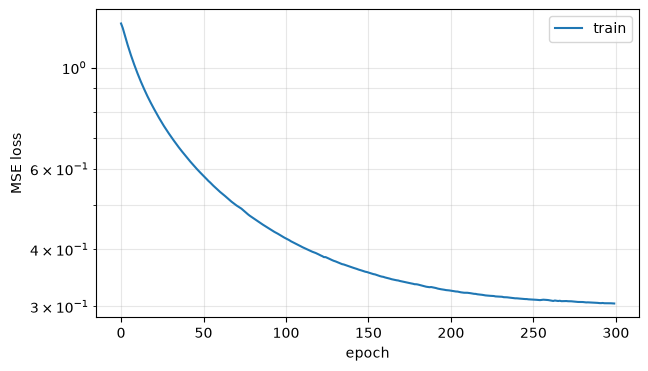

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='train')
plt.yscale('log')
plt.xlabel('epoch')
plt.ylabel('MSE loss')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

In [8]:
test_loss = model.evaluate(test_input, test_output, verbose=0)
print(f"Test loss (MSE): {test_loss:.6f}")

pred = model.predict(test_input, verbose=0)

Test loss (MSE): 0.307791


Text(0.5, 1.0, 'predicted')

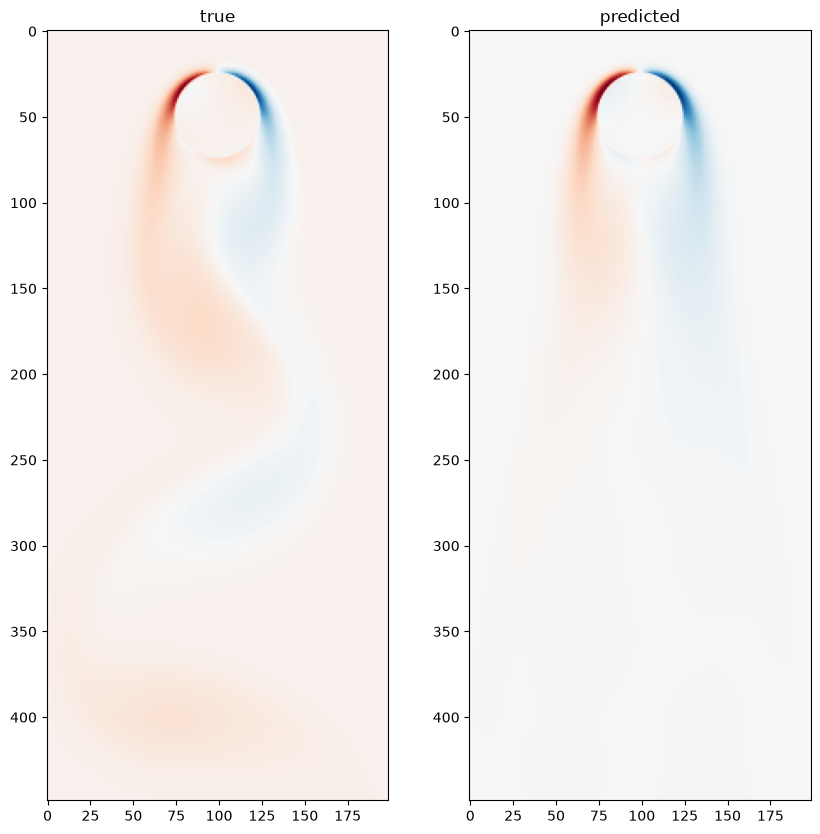

In [9]:
# Plotting the first test sample, true vs predicted 
step = 1
fig, ax = plt.subplots(1, 2, figsize=(10, 10))
ax[0].imshow(test_output[step].reshape(ny, nx), cmap='RdBu_r'); ax[0].set_title('true')
ax[1].imshow(pred[step].reshape(ny, nx), cmap='RdBu_r');       ax[1].set_title('predicted')

The above network has been trained using trail and error for setting up the hyper parameters. The number of epochs, the optimizer and the learning rate been tuned manually, while the percentage of training vs test data and the neural network architecutre have been kept constant. It would ofcourse have been better to use a validation set to tune the hyperparameters, but with "only" 151 datapoints and limited computer power tis was done manually.

However, the neural network created using the RNN structure is trained rather well now and the percentage of datapoints, P, can now be changed to see how this affects the neural network. 10 networks will be trained using P = [0.99, 0.95, 0.85, 0.75, 0.65, 0.55, 0.45, 0.35, 0.25, 0.15]

With the current setup having 20 snapshots in the sequence it is not possible to go below P = 0.15, as this would make the training set have less than 20 snapshots. With P = 0.15 there are 23 snapshots in the training set, having only 3 datapoints to train on, which is expected to perform quite bad. All the same hyperparameters are used for all P-values

In [10]:
# Creating a function to call to build the model before each run
def build_model(n_feat):
    model = Sequential()
    model.add(SimpleRNN(16, input_shape=(None, n_feat)))
    model.add(Dense(n_feat))
    model.compile(optimizer=Adam(1e-3), loss='mean_squared_error')
    return model

In [ ]:
# Looping over the percentage used in data/test
P_list = [0.99, 0.95, 0.85, 0.75, 0.65, 0.55, 0.45, 0.35, 0.25, 0.15]

test_loss_list = []

for P in P_list:
    
    t_train = round(t*P)
    t_test = t - t_train  

    train_size = t_train; test_size = t_test;
    # Number of training intervals
    n_train = train_size - sequence_size
    # Creating matrices for the input and output for training
    rnn_input = np.zeros((n_train, sequence_size, n_feat))
    rnn_output = np.zeros((n_train, n_feat))

    # Creating matrices for the input and output for training
    n_test = t_test
    test_input = np.zeros((n_test, sequence_size, n_feat))
    test_output = np.zeros((n_test, n_feat))

    for i in range(n_train):
        rnn_input[i] = VORTALL[i : i + sequence_size, :]
        rnn_output[i] = VORTALL[i + sequence_size, :]

    for i in range(n_test):
        start = t_train - sequence_size + i
        test_input[i] = VORTALL[start : start + sequence_size, :]
        test_output[i] = VORTALL[start + sequence_size, :]
    
    
    model = build_model(n_feat)
    model.fit(rnn_input, rnn_output, epochs = epochs, verbose = 0)
    test_loss = model.evaluate(test_input, test_output, verbose=0)
    test_loss_list.append(test_loss)
    print(f"P={P:.2f}  test={test_loss:.5f}")

/opt/homebrew/Caskroom/miniforge/base/envs/ml/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(P_list, test_loss_list, 'o-', label='test')
plt.yscale('log')
plt.xlabel('P (fraction of data used for training)')
plt.ylabel('MSE loss')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.show()